In [1]:
import polars as pl
import pandas as pd
import numpy as np
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import MinMaxScaler

In [2]:
df = pd.read_csv("../../data/customer_churn_dataset-training-master.csv")
test_df = pd.read_csv("../../data/customer_churn_dataset-testing-master.csv")

**Data Analysis Begins**

In [3]:
df.shape

(440833, 12)

In [4]:
df.columns

Index(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype='str')

In [5]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [6]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000,440832.000000
mean,225398.667955,39.373153,31.256336,15.807494,3.604437,12.965722,631.616223,14.480868,0.567107
std,129531.918550,12.442369,17.255727,8.586242,3.070218,8.258063,240.803001,8.596208,0.495477
min,2.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,113621.750000,29.000000,16.000000,9.000000,1.000000,6.000000,480.000000,7.000000,0.000000
50%,226125.500000,39.000000,32.000000,16.000000,3.000000,12.000000,661.000000,14.000000,1.000000
75%,337739.250000,48.000000,46.000000,23.000000,6.000000,19.000000,830.000000,22.000000,1.000000
max,449999.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


**Findings**
1. Total input training records 440,883 with 12 columns.
2. Based on describe & checking subscription type, there are 440832 records across the columns indicating 1 record  having null values.
3. Customers are in range of 18 to 65 years old
4. Customers have spend from 100 USD to 1000 USD amount

**Exploratory Data Analysis**

**Step 1 preprocessing - convert string to numbers**

In [7]:
df = df.dropna()

In [8]:
df.shape

(440832, 12)

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
numeric_df = df.select_dtypes(include=["number"])

In [12]:
corr_matric = numeric_df.corr()
plt.figure(figsize=(10,8))

<Figure size 1000x800 with 0 Axes>

<Figure size 1000x800 with 0 Axes>

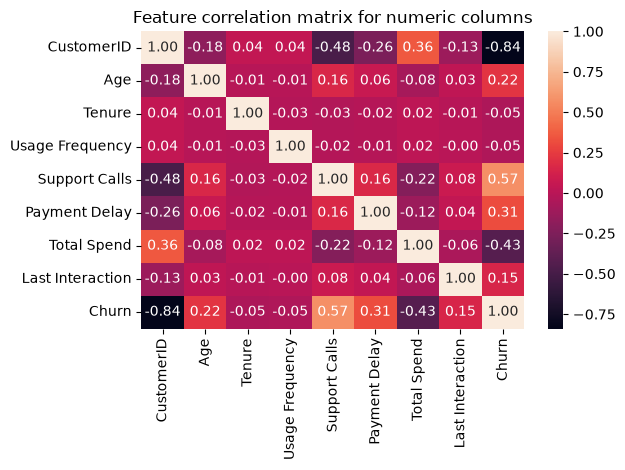

In [13]:
sns.heatmap(corr_matric, annot=True, fmt=".2f")
plt.title("Feature correlation matrix for numeric columns")
plt.tight_layout()
plt.show()

**From Heatmap:**
1 postive correlation exists for churn with age , support calls , payment delays and someone wiht last interaction.
2. Total spen is inversely related with churn.
3. Tenure doesnt seems to have much relation with churn

**Determine outliers in variables or features using box plots**

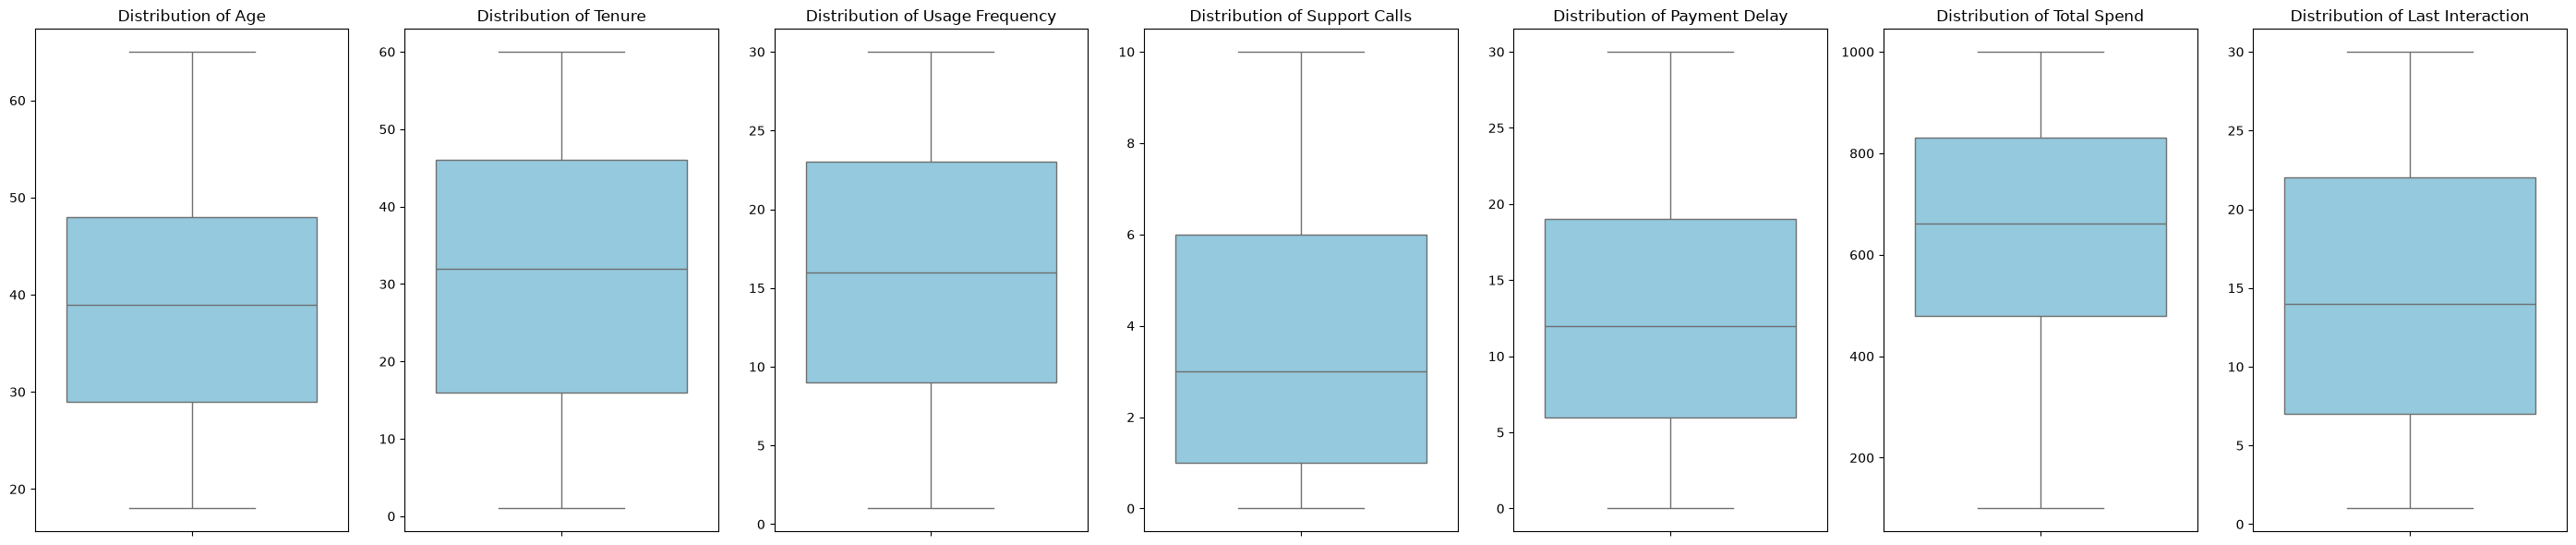

In [13]:
cols_to_plot = numeric_df.drop(columns=["CustomerID", "Churn"], errors="ignore")

# 2. Set up a grid of subplots dynamically based on the number of features
num_cols = len(cols_to_plot.columns)
fig, axes = plt.subplots(
    nrows=1, ncols=num_cols, figsize=(4 * num_cols, 6), sharey=False
)

# 3. Loop through columns and plot each on its own axis
for i, col in enumerate(cols_to_plot.columns):
    sns.boxplot(data=cols_to_plot, y=col, ax=axes[i], color="skyblue")
    axes[i].set_title(f"Distribution of {col}", fontsize=12)
    axes[i].set_ylabel("")  # Clears y-label so it doesn't crowd the title

# 4. Clean up the spacing and show the plot
plt.tight_layout()
plt.show()

In [22]:
onehot_categorical_cols = ["Subscription Type", "Contract Length"]

In [23]:
X_encoded = pd.get_dummies(df, columns=onehot_categorical_cols,drop_first=True)

In [24]:
gender_map = {"Female":0,"Male":1}
X_encoded["Gender"] = X_encoded["Gender"].map(gender_map)

In [25]:
X_encoded = X_encoded.astype(float)

In [26]:
X_encoded.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Monthly,Contract Length_Quarterly
0,2.0,30.0,0.0,39.0,14.0,5.0,18.0,932.0,17.0,1.0,0.0,1.0,0.0,0.0
1,3.0,65.0,0.0,49.0,1.0,10.0,8.0,557.0,6.0,1.0,0.0,0.0,1.0,0.0
2,4.0,55.0,0.0,14.0,4.0,6.0,18.0,185.0,3.0,1.0,0.0,0.0,0.0,1.0
3,5.0,58.0,1.0,38.0,21.0,7.0,7.0,396.0,29.0,1.0,0.0,1.0,1.0,0.0
4,6.0,23.0,1.0,32.0,20.0,5.0,8.0,617.0,20.0,1.0,0.0,0.0,1.0,0.0


In [27]:
y = X_encoded[['Churn']]
X_encoded = X_encoded.drop(columns=['Churn','CustomerID'])

In [28]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.25, random_state=42)

**Training/Prediction using Random Forest classifier**

In [29]:
from sklearn.ensemble import RandomForestClassifier

In [93]:
rf_model = RandomForestClassifier(random_state=42, class_weight='balanced',n_jobs=-1,max_depth=3,n_estimators=24)

In [94]:
rf_model.fit(X_train, y_train.values.ravel())

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",24
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_featur

In [33]:
from sklearn.metrics import classification_report,roc_auc_score
from sklearn.metrics import RocCurveDisplay

In [95]:
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)[:, 1]

print("Classification Report using training data:")
print(classification_report(y_test, y_pred))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_pred_proba):.4f}")

Classification Report using training data:
              precision    recall  f1-score   support

         0.0       0.91      0.99      0.95     47637
         1.0       0.99      0.93      0.96     62571

    accuracy                           0.96    110208
   macro avg       0.95      0.96      0.96    110208
weighted avg       0.96      0.96      0.96    110208

ROC AUC Score: 0.9908


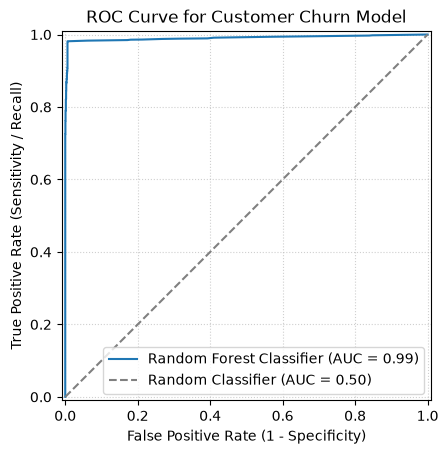

In [96]:
display = RocCurveDisplay.from_estimator(
    rf_model, 
    X_test, 
    y_test, 
    name="Random Forest Classifier"
)

# 2. Add cosmetic details to make it clear and professional
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve for Customer Churn Model")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

# 3. Render the plot
plt.show()

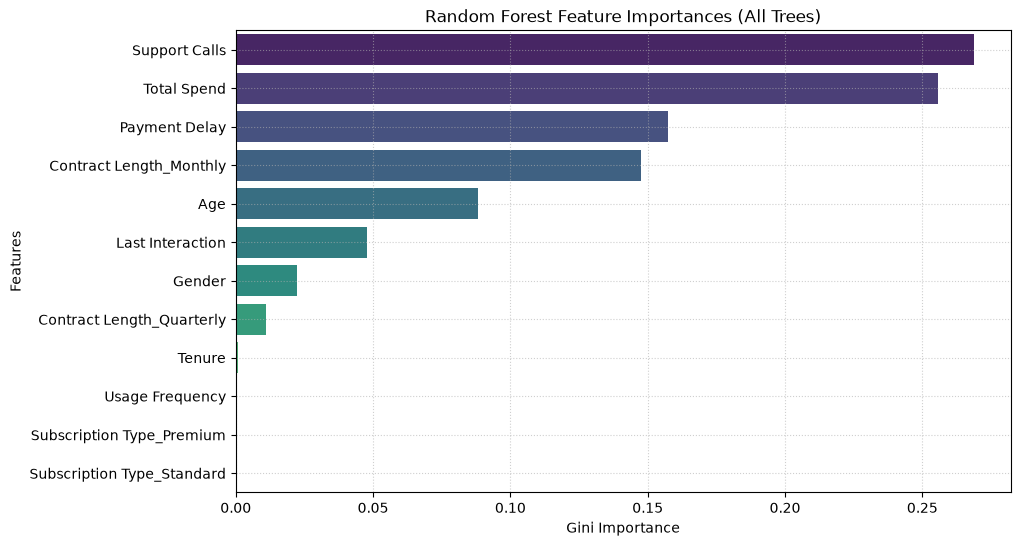

In [97]:


# Extract and sort feature importances
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index,palette="viridis")
plt.xlabel("Gini Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importances (All Trees)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

**Using Test data to run through prediction using model generated out of training data**

In [83]:
test_df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [84]:
y_test_actual = test_df['Churn']
X_test_raw = test_df.drop(columns=['Churn','CustomerID'])

X_test_raw_encoded = pd.get_dummies(X_test_raw, columns=onehot_categorical_cols,drop_first=True)
X_test_raw_encoded["Gender"] = X_test_raw_encoded["Gender"].map(gender_map)
X_test_raw_encoded = X_test_raw_encoded.astype(float)

X_test_raw_encoded = X_test_raw_encoded.reindex(columns=X_train.columns, fill_value=0)

In [98]:
y_test_preds = rf_model.predict(X_test_raw_encoded)


In [99]:
y_test_probs = rf_model.predict_proba(X_test_raw_encoded)[:, 1]
print("Classification Report using test data:")
print(classification_report(y_test_actual, y_test_preds))
print(f"ROC AUC Score: {roc_auc_score(y_test_actual, y_test_probs):.4f}")

Classification Report using test data:
              precision    recall  f1-score   support

           0       0.96      0.15      0.26     33881
           1       0.51      0.99      0.68     30493

    accuracy                           0.55     64374
   macro avg       0.73      0.57      0.47     64374
weighted avg       0.75      0.55      0.45     64374

ROC AUC Score: 0.7624


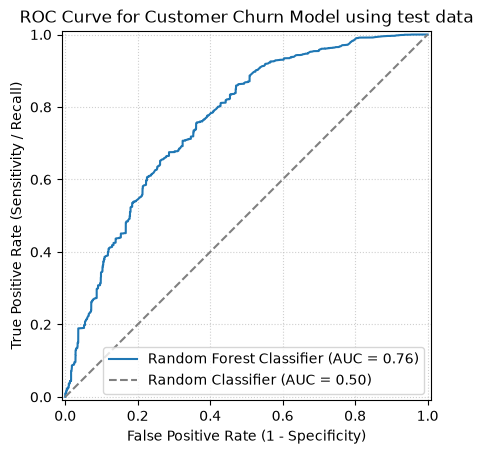

In [100]:
display = RocCurveDisplay.from_estimator(
    rf_model, 
    X_test_raw_encoded, 
    y_test_actual, 
    name="Random Forest Classifier"
)

# 2. Add cosmetic details to make it clear and professional
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Classifier (AUC = 0.50)")
plt.title("ROC Curve for Customer Churn Model using test data")
plt.xlabel("False Positive Rate (1 - Specificity)")
plt.ylabel("True Positive Rate (Sensitivity / Recall)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)

# 3. Render the plot
plt.show()

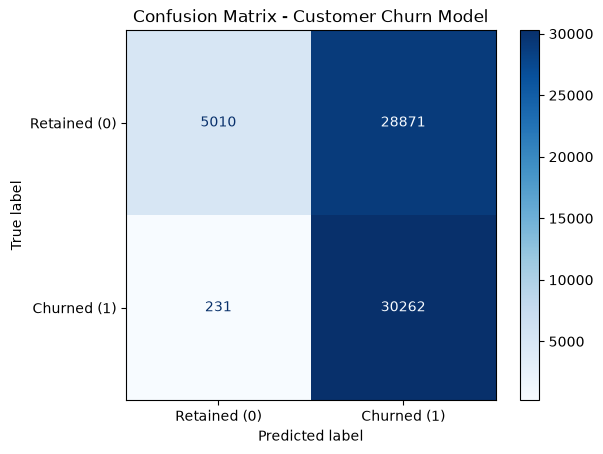

In [101]:
#1. Generate the confusion matrix from  test predictions
# This uses your true labels (y_test_actual) and the predicted classes (y_test_preds)
display = ConfusionMatrixDisplay.from_predictions(
    y_test_actual,
    y_test_preds,
    values_format='d',
    display_labels=["Retained (0)", "Churned (1)"],
    cmap=plt.cm.Blues
)

# 2. Add titles and cosmetic details
plt.title("Confusion Matrix - Customer Churn Model")
plt.grid(False) # Turn off the default background grid lines for a cleaner look

# 3. Render the plot
plt.show()

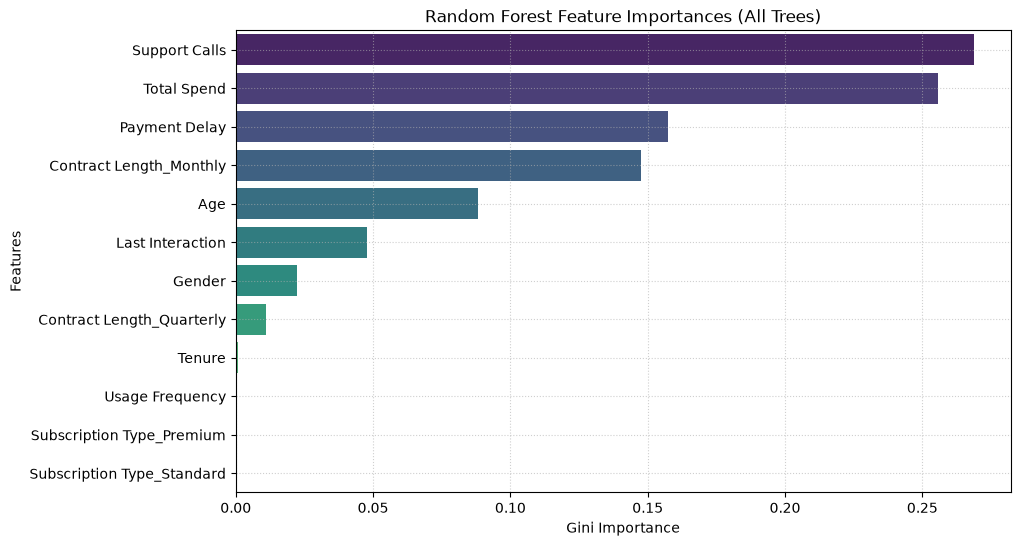

In [102]:


# Extract and sort feature importances
importances = pd.Series(rf_model.feature_importances_, index=X_test_raw_encoded.columns).sort_values(ascending=False)

# Plot feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index,palette="viridis")
plt.xlabel("Gini Importance")
plt.ylabel("Features")
plt.title("Random Forest Feature Importances (All Trees)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [103]:
individual_tree = rf_model.estimators_[0]

In [69]:
individual_tree

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",'sqrt'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1608637542
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofs

In [71]:
from sklearn.tree import plot_tree

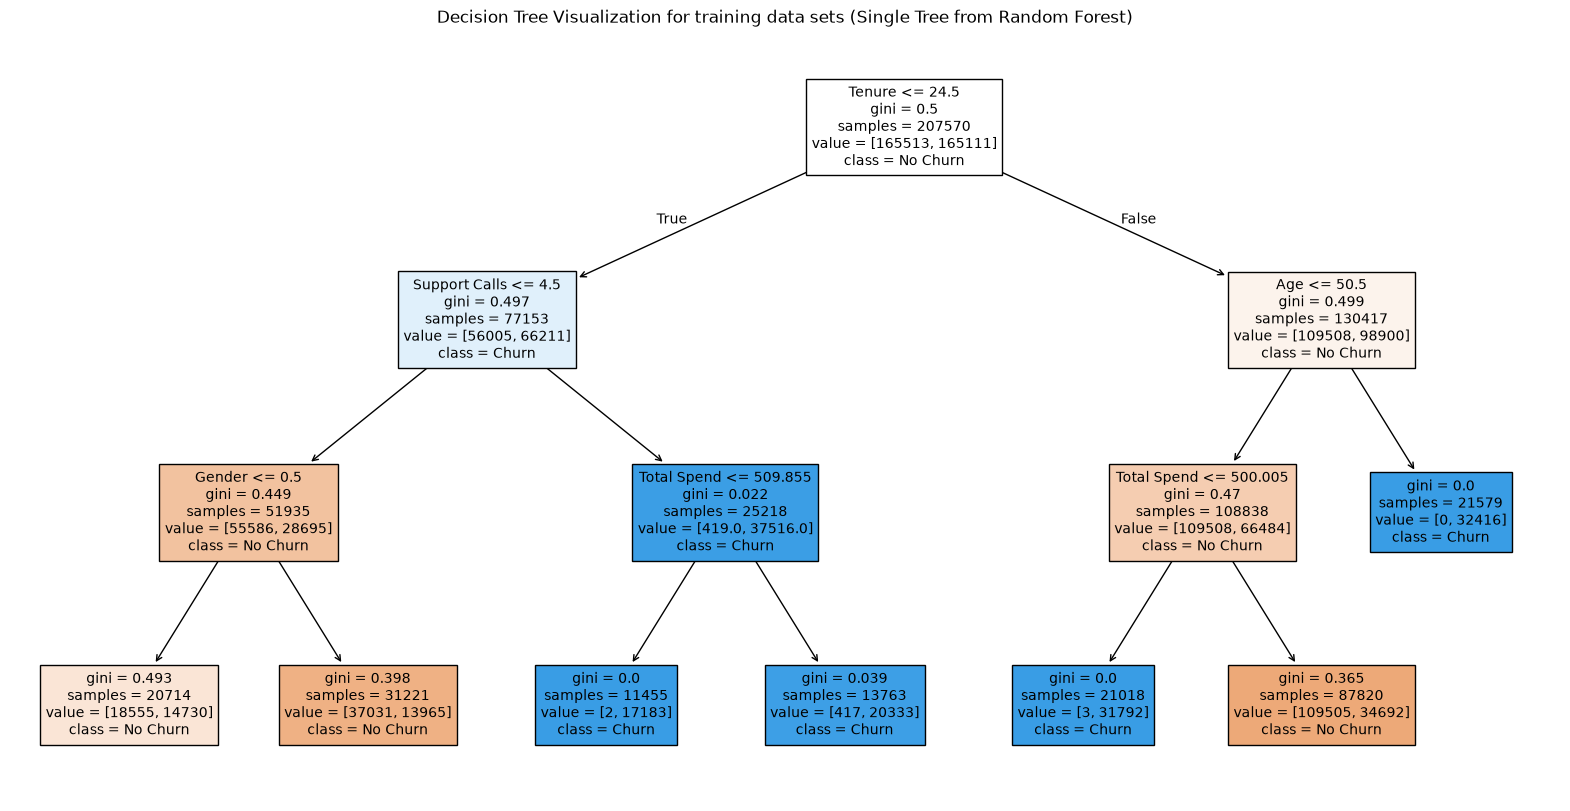

In [104]:
plt.figure(figsize=(20, 10))
plot_tree(
    individual_tree,
    feature_names=X_train.columns,
    class_names=['No Churn', 'Churn'],
    filled=True,
    max_depth=3,  # Limit depth so the visualization remains readable
    fontsize=10
)
plt.title("Decision Tree Visualization for training data sets (Single Tree from Random Forest)")
plt.show()

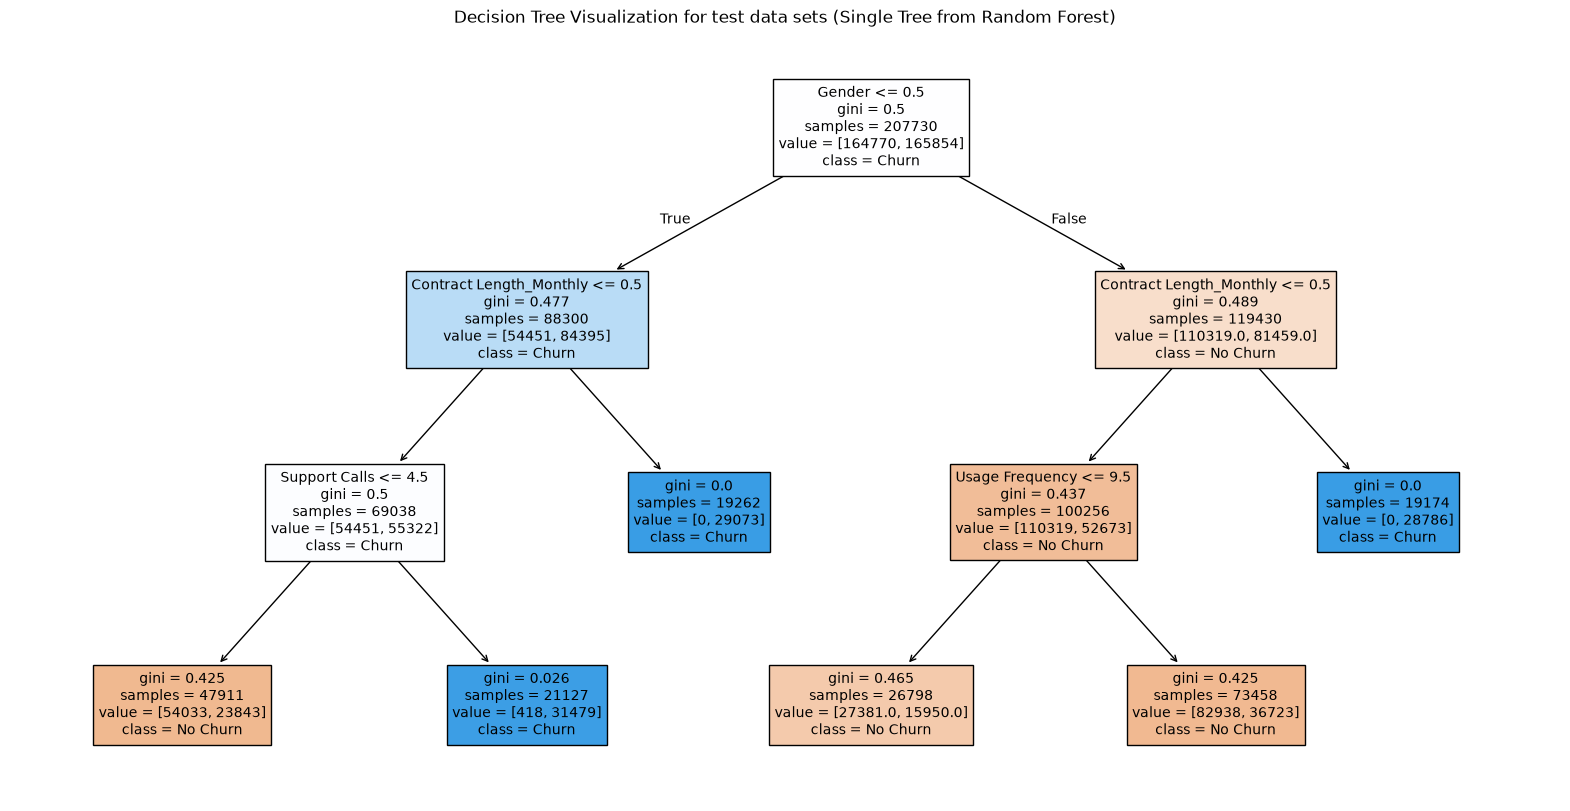

In [105]:
plt.figure(figsize=(20, 10))
plot_tree(
    rf_model.estimators_[23],
    feature_names=X_test_raw_encoded.columns,
    class_names=['No Churn', 'Churn'],
    filled=True,
    max_depth=3,  # Limit depth so the visualization remains readable
    fontsize=10
)
plt.title("Decision Tree Visualization for test data sets (Single Tree from Random Forest)")
plt.show()